# 08 · Review Diagnosis

**Goal:** understand why entries whose top pick is already right still go to review, and whether a better step 2 can decide more of them without lowering precision.

The diagnosis uses TRAIN with cross-validated probabilities, the same way notebook 04 tunes step 2. VAL is only used to check the fix. TEST and the holdout file aren't used.

**Questions**
1. How many entries in review already have the right matter on top?
2. Are they held back for a good reason, or is step 2 leaving signal on the table?
3. What do these entries look like?
4. Does a better-tuned action model decide more of them at the same precision?

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import PredefinedSplit, cross_val_predict

sys.path.insert(0, "../src")
from rules import answer_key, score, summarize, precision_ci
from classifier import entry_features, action_labels, route_actions, two_step, ACTION_FEATURES

In [2]:
RESULTS_DIR = Path("../results")
SEED = 210
SETTING = "default"
TARGET = 0.97

ORIGINAL_ACTION_GRID = {"n_estimators": [50, 100, 200], "min_child_samples": [50, 100, 200]}
ACTION_GB_GRID = {"n_estimators": [50, 100, 200], "num_leaves": [4, 7, 31], "min_child_samples": [20, 50, 100]}
ACTION_GRID = {
    "auto_min": [0.5, 0.7, 0.8, 0.85, 0.9, 0.93, 0.95, 0.97, 0.98, 0.99, 0.995],
    "no_match_min": [0.3, 0.5, 0.7, 0.9, 0.95],
}
MULTI_GRID = np.round(np.arange(0.05, 0.95, 0.05), 2)
MULTI_BETA = 2
CORRECT_TYPED_CMID = True
ROBUST_SHARE = 0.9

CLUES = ["top_prob", "top_share", "second_prob", "has_cmid", "has_client", "has_matter", "best_client_score",
         "best_matter_score", "top_in_history", "top_past_sim", "n_other_sources", "n_parts", "multi_text_score"]

## 2. Load data

Same pairs table and folds as notebook 04, plus its saved models and the default cutoffs.

In [3]:
pairs = pd.read_parquet(RESULTS_DIR / "02_pairs.parquet")
feature_config = json.loads((RESULTS_DIR / "02_config.json").read_text())
config_04 = json.loads((RESULTS_DIR / "04_config.json").read_text())
models = joblib.load(RESULTS_DIR / "04_model.joblib")
answers = answer_key(pairs)
narratives = pairs.drop_duplicates("entry_id").set_index("entry_id")["narrative_norm"]

FEATURES = config_04["features"]
CLIENT_COL, MATTER_COL = feature_config["client_col"], feature_config["matter_col"]
cutoffs = config_04["routing"][SETTING]

train_pairs = pairs[pairs["split"] == "TRAIN"].reset_index(drop=True)
val_pairs = pairs[pairs["split"] == "VAL"].reset_index(drop=True)
cv = PredefinedSplit(train_pairs["fold"])

assert config_04["action_features"] == ACTION_FEATURES
assert train_pairs.groupby("entry_id")["fold"].nunique().eq(1).all()
print(f"TRAIN: {train_pairs['entry_id'].nunique():,} entries | VAL: {val_pairs['entry_id'].nunique():,} entries")
print(f"{SETTING} cutoffs:", cutoffs)

TRAIN: 2,802 entries | VAL: 601 entries
default cutoffs: {'auto_min': 0.9, 'no_match_min': 0.9, 'multi_min': 0.15, 'correct_typed_cmid': True}


## 3. Rebuild step 2 on TRAIN

Every TRAIN entry is scored by models that never saw it: cross-validated pair probabilities, then cross-validated action probabilities, with notebook 04's settings and the default cutoffs. The summary should match notebook 04's default row on TRAIN.

In [4]:
train_probs = cross_val_predict(models["pair_model"], train_pairs[FEATURES], train_pairs["is_true_matter"], cv=cv,
                                method="predict_proba")[:, 1]
entries = entry_features(train_pairs, train_probs, CLIENT_COL, MATTER_COL, feature_config["phrase_min"])
entries["label"] = action_labels(entries, answers)
entry_folds = entries["entry_id"].map(train_pairs.drop_duplicates("entry_id").set_index("entry_id")["fold"])
entry_cv = PredefinedSplit(entry_folds)

narrative_train = entries["entry_id"].map(narratives)
entries["multi_text_score"] = cross_val_predict(models["text_model"], narrative_train, entries["label"] == "multi",
                                                cv=entry_cv, method="predict_proba")[:, 1]
action_probs = pd.DataFrame(cross_val_predict(models["action_model"], entries[ACTION_FEATURES], entries["label"], cv=entry_cv,
                                              method="predict_proba"), columns=models["action_model"].classes_)
decisions = route_actions(entries, action_probs, cutoffs)
entries["p_auto"] = action_probs["auto"].to_numpy()
entries["action"] = decisions["action"].to_numpy()

s = summarize(score(decisions, answers))
print(f"TRAIN, {SETTING}: decided precision {s['decided_precision']:.3f} | straight-through {s['straight_through']:.3f} | "
      f"review {s['review_share']:.3f}")

TRAIN, default: decided precision 0.978 | straight-through 0.717 | review 0.153


## 4. Who is in review?

The action label says what should have happened to each entry:
- `auto`: the top pick is right and safe to accept
- `review`: the top pick is wrong
- `multi` and `no_match`: multi-matter entries and new clients or matters

In [5]:
review = entries[entries["action"] == "NEEDS_REVIEW"]
held = review[review["label"] == "auto"]
print(f"{len(review)} TRAIN entries sent to review | right matter on top and safe to accept: {len(held)} ({len(held) / len(review):.0%})")
review["label"].value_counts().rename("entries in review").to_frame()

430 TRAIN entries sent to review | right matter on top and safe to accept: 250 (58%)


,entries in review
label,
auto,250
review,100
no_match,70
multi,10


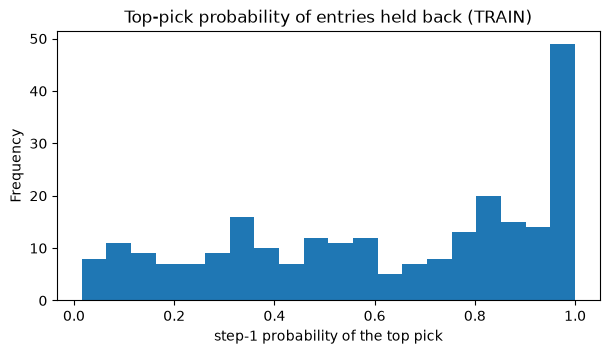

In [6]:
ax = held["top_prob"].plot.hist(bins=20, figsize=(7, 3.5), title="Top-pick probability of entries held back (TRAIN)")
ax.set_xlabel("step-1 probability of the top pick")
plt.show()

- **More than half of review already has the right matter on top:** 250 of 430 TRAIN entries in review. The rest have a wrong top pick (100), are new clients the new-client cutoff didn't call (70), or cover two matters (10).
- **Many of them have a confident top pick:** about 100 score above 0.8 in step 1, so the pair model was sure but step 2 wasn't. The rest are spread across every probability.

## 5. Are they held back for a good reason?

If P(auto) is trustworthy, entries just below `auto_min` should be safe noticeably less often than the 97% target, and holding them back is the target doing its job. If they're safe about as often as accepted ones, step 2 is too cautious. The plot compares predicted P(auto) with how often the entry really was safe.

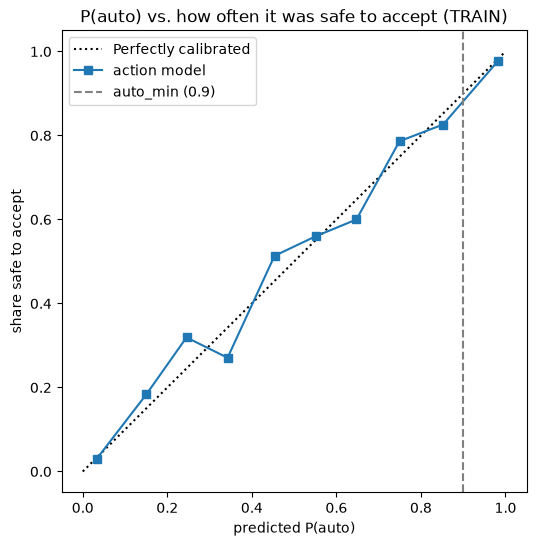

,entries,predicted,actual
p_auto,,,
"(0.0, 0.5]",457,0.171,0.184
"(0.5, 0.7]",170,0.605,0.582
"(0.7, 0.8]",103,0.749,0.786
"(0.8, 0.85]",76,0.826,0.750
"(0.85, 0.9]",85,0.876,0.894
"(0.9, 0.93]",100,0.916,0.920
"(0.93, 0.95]",104,0.940,0.962
"(0.95, 0.97]",178,0.961,0.933
"(0.97, 0.99]",403,0.982,0.970


In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
CalibrationDisplay.from_predictions(entries["label"] == "auto", entries["p_auto"], n_bins=10, name="action model", ax=ax)
ax.axvline(cutoffs["auto_min"], color="gray", linestyle="--", label=f"auto_min ({cutoffs['auto_min']})")
ax.set(title="P(auto) vs. how often it was safe to accept (TRAIN)", xlabel="predicted P(auto)", ylabel="share safe to accept")
ax.legend()
plt.show()

bands = pd.cut(entries["p_auto"], [0, 0.5, 0.7, 0.8, 0.85, 0.9, 0.93, 0.95, 0.97, 0.99, 1])
entries.groupby(bands, observed=True).agg(entries=("label", "size"), predicted=("p_auto", "mean"),
                                          actual=("label", lambda s: (s == "auto").mean())).round(3)

- **P(auto) is close to calibrated,** so it can be trusted as a confidence score.
- **Entries just below the cutoff are held back for a good reason:** between 0.8 and 0.9, only 75% to 89% are safe to accept, well under the 97% target. Accepting them would lower precision.
- **The target is met through the mix:** the bands from 0.9 to 0.97 are safe 92% to 96% of the time, and the 1,126 entries above 0.99 (99.5% safe) carry the overall rate above 97%.

## 6. What do they look like?

The held-back entries next to the ones accepted correctly, on the clues step 2 sees. These are averages, so flags read as shares.

In [8]:
accepted = entries[(entries["action"] == "AUTO_MATCH") & (entries["label"] == "auto")]
pd.DataFrame({"held back": held[CLUES].mean(), "accepted, right": accepted[CLUES].mean()}).round(3)

,held back,"accepted, right"
top_prob,0.616,0.967
top_share,0.766,0.953
second_prob,0.142,0.031
has_cmid,0.392,0.491
has_client,0.612,0.787
has_matter,0.176,0.406
best_client_score,56.921,76.837
best_matter_score,13.719,34.684
top_in_history,0.632,0.759
top_past_sim,0.459,0.637


In [9]:
confident = entries[entries["top_prob"] >= 0.9]
pd.crosstab(confident["action"], confident["label"], margins=True)

label,auto,multi,no_match,review,All
action,,,,,
AUTO_MATCH,1721,16,1,15,1753
FLAG_MISMATCH,4,0,0,2,6
MULTI_MATTER,37,96,0,1,134
NEEDS_REVIEW,65,3,0,5,73
All,1827,115,1,23,1966


- **Held-back entries have less to go on:** fewer typed clients (61% vs. 79%) and matters (18% vs. 41%), lower name scores, a top pick the timekeeper has billed less often (63% vs. 76%), and narratives less like past entries (0.46 vs. 0.64). Their second pick is also closer (0.14 vs. 0.03).
- **Among entries with a confident top pick (0.9 or above), step 2 sorts well:** 1,721 of 1,827 safe entries are accepted, 96 of 115 multi-matter entries get the call, and only 65 safe entries go to review.
- So review isn't step 2 leaving signal on the table: the held-back entries mostly lack the clues that make an entry safe to accept.

## 7. Does a better-tuned action model help?

The action model only has about 2,800 TRAIN entries to learn from, so smaller trees might generalize better. The original grid only tuned the number of trees and leaf size. The wider grid also tries smaller trees (`num_leaves` 4 and 7, vs. the default 31).

Both grids go through `two_step` with the same pair probabilities. The grid search picks each action model by log loss on TRAIN, and cutoffs are picked at the 97% target with the same margin as notebook 04. **The choice is made on TRAIN's log loss;** VAL only checks it.

In [10]:
val_probs = models["pair_model"].predict_proba(val_pairs[FEATURES])[:, 1]

results = {}
for name, grid in [("original grid", ORIGINAL_ACTION_GRID), ("wider grid", ACTION_GB_GRID)]:
    scored, cfg, search = two_step(train_pairs, train_probs, val_pairs, val_probs, answers, narratives, models["text_model"],
                                   CLIENT_COL, MATTER_COL, TARGET, grid, ACTION_GRID, MULTI_GRID, MULTI_BETA,
                                   CORRECT_TYPED_CMID, SEED, ROBUST_SHARE)
    s = summarize(scored)
    s["ci_low"], s["ci_high"] = precision_ci(scored)
    results[name] = {"train_log_loss": -search.best_score_, "settings": search.best_params_, "auto_min": cfg["auto_min"], **s}

pd.DataFrame(results).T.infer_objects()[["train_log_loss", "settings", "auto_min", "decided_precision", "ci_low", "ci_high", "straight_through",
                         "review_share", "silent_errors", "multi_caught"]].round(3)

,train_log_loss,settings,auto_min,decided_precision,ci_low,ci_high,straight_through,review_share,silent_errors,multi_caught
original grid,0.271,"{'min_child_samples': 100, 'n_estimators': 50}",0.9,0.975,0.959,0.987,0.719,0.160,8,0.811
wider grid,0.259,"{'min_child_samples': 20, 'n_estimators': 100,...",0.9,0.977,0.964,0.989,0.735,0.151,9,0.811


- **The wider grid fits better on TRAIN** (log loss 0.259 vs. 0.271) and picks smaller trees (7 leaves).
- **On VAL it decides slightly more with no person** (73.5% vs. 71.9%) at about the same precision (97.7% vs. 97.5%), with one more silent error. That gap is within the noise of about 600 entries, so the wider grid is kept because it fits TRAIN better, not because of VAL.

## 8. Findings

### Results
- **More than half of review already has the right matter on top** (58% on TRAIN), so most reviews are a quick confirmation.
- **They're held back for a good reason:** P(auto) is close to calibrated, and entries just below the cutoff are safe only 75% to 89% of the time, under the 97% target.
- **Held-back entries have less to go on:** fewer typed fields, less billing history with the top pick, and narratives less like past ones.
- **A wider grid with smaller trees fits TRAIN better** and is what notebook 04 uses. On VAL it decides about 1.5 points more with no person at the same precision, within the noise.

### Tradeoff
- **Accepting held-back entries would cut review but break the target.** Their top pick is usually right, but "usually" here is 75% to 89%, and every extra wrong auto-match is a silent error. Review time is the cheaper cost.

### What would help instead
- **More data more than a different step 2:** notebook 07's learning curve is still rising.
- **Feedback from reviewers:** confirmed entries add billing history, which is what held-back entries lack (notebook 09).

### Limitations
- The diagnosis uses cross-validated probabilities, which are slightly weaker than a model refit on all of TRAIN.
- The grid comparison rests on about 600 VAL entries, so it can't separate gaps of 1 to 2 points from noise.